# Turtle Breakout 16 — the turtle on futures (its native market), each contract in its own account

Pre-registration: `discussions/Turtle_Breakout/018_claude_tb16_preregistration.md`. Code: `turtle_stock_accounts.py`, `turtle_stocks.py` (unchanged); universe `16/16_universe.csv`; data `tools/download_tb16_futures.py` (Yahoo, downloaded on the first run if missing).

**FUT (decision):** 41 continuous front-month futures (energy, metals, grains, softs, livestock, rates, FX, equity indices), 2000 → last session, each in its own account with the TB 01 rules (2% of HWM per trade, ≤ 3× notional), long and long + reverse; 2 bp per side, no borrow. **ETF (reported):** 18 futures-proxy ETFs, 5 bp, borrow 0.5%/yr.
Each instrument uses its own trading calendar (sessions as consecutive periods), O→H→L→C fills.
**G1** pooled mean R of real longs − random-entry longs (50 runs) ≥ 0.10R **and** per-contract differences above the calibrated fill artefact (+0.045R), t-test p < 0.025. **G2** contracts with Calmar(long + reverse) > Calmar(long): sign test p < 0.025.

Environment: `TB16_DATA` (default `<parent of DERIBIT_DATA_ROOT>/Stocks/tb16/futures_daily.parquet`), `TB16_SYNTHETIC=1`.

In [1]:
import os, sys, json, gc, time, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_sizing as ts, turtle_reverse as tr, turtle_portfolio as tp, turtle_stocks as tk, turtle_stock_accounts as ta

SYNTHETIC = os.getenv('TB16_SYNTHETIC', '0') == '1'
UNI = pd.read_csv(ROOT / 'notebooks' / 'Turtle_Breakout' / '16' / '16_universe.csv')
COSTS = {'fut': {'side_cost': 0.0002, 'borrow': 0.0}, 'etf': {'side_cost': 0.0005, 'borrow': 0.005}}
FUT_COST_HIGH = 0.0005
AP0 = replace(ta.AParams(), status='PREREGISTERED_TB018', seed=20261028)
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb16-')) / '16'; AP0 = replace(AP0, n_null=10)
    UNI = UNI.groupby('set').head(8).reset_index(drop=True)
    rows = []
    for i, t in enumerate(UNI.ticker):
        d, _ = tk.synthetic_daily(2600, seed=70 + i, drift=0.0001)
        rows.append(d.assign(ticker=t).rename_axis('date').reset_index())
    RAW = pd.concat(rows, ignore_index=True)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '16'
    root = Path(os.environ['DERIBIT_DATA_ROOT']).parent
    DATA_FILE = Path(os.environ.get('TB16_DATA', str(root / 'Stocks' / 'tb16' / 'futures_daily.parquet')))
    if not DATA_FILE.exists():
        sys.path.insert(0, str(ROOT / 'tools')); import download_tb16_futures as dl
        DATA_FILE = dl.download(DATA_FILE.parent)
    RAW = pd.read_parquet(DATA_FILE)
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_stock_accounts.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
RAW['date'] = pd.to_datetime(RAW['date']).dt.tz_localize(None).dt.normalize()
RAW = RAW[RAW.date >= pd.Timestamp('2000-01-03')]
print('rows', len(RAW), '| tickers', RAW.ticker.nunique(), 'of', len(UNI), '| missing:', sorted(set(UNI.ticker) - set(RAW.ticker)))
print(json.dumps({**ta.registration(AP0), 'costs': COSTS, 'fut_cost_high': FUT_COST_HIGH}, indent=1))

59 tickers, 1999-10-01 -> 2026-10-28
  20/59: 20 tickers with data


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: DX=F"}}}
$DX=F: possibly delisted; no timezone found

1 Failed download:
['DX=F']: possibly delisted; no timezone found


  40/59: 19 tickers with data
  59/59: 19 tickers with data
saved 351,036 rows, 58 tickers; missing: 1 -> D:\MarketData\Stocks\tb16\stocks_daily.parquet
renamed -> D:\MarketData\Stocks\tb16\futures_daily.parquet
OK
rows 350912 | tickers 58 of 59 | missing: ['DX=F']
{
 "risk_frac": 0.02,
 "pos_cap": 3.0,
 "size_base": "hwm",
 "side_cost": 0.0005,
 "borrow": 0.005,
 "n_null": 50,
 "min_effect_R": 0.1,
 "alpha": 0.05,
 "n_tests": 2,
 "seed": 20261028,
 "status": "PREREGISTERED_TB018",
 "version": "TB15-0.2.0",
 "rules": "TB 01 per stock: 2% of HWM per trade, 3x notional cap; reverse = TB 07",
 "gates": {
  "G1": "pooled mean R of real longs > random-entry longs (50 runs, z-test, p < alpha/2) and difference >= 0.10R",
  "G2": "stocks with Calmar(long_rev) > Calmar(long): sign test p < alpha/2"
 },
 "reported": [
  "per stock CAGR, max DD, Calmar, Sharpe, ruin for long, long + reverse, buy and hold",
  "share of stocks with positive CAGR; beating buy and hold on Calmar",
  "mean R of revers

## 1. Every contract / ETF in its own account

In [2]:
def gaps(d):
    pc = d.close.shift(1); tr_ = pd.concat([d.high - d.low, (d.high - pc).abs(), (d.low - pc).abs()], axis=1).max(axis=1)
    atr = tr_.ewm(alpha=1 / 20, adjust=False).mean().shift(1)
    return int(((d.open - pc).abs() > 3 * atr).sum())

ROWS, CURVES = [], {s: {'long': {}, 'long_rev': {}, 'hold': {}, 'long_costhigh': {}, 'long_rev_costhigh': {}} for s in COSTS}
NULL = {s: [np.zeros(AP0.n_null), np.zeros(AP0.n_null)] for s in COSTS}; REAL = {s: [0.0, 0] for s in COSTS}
rng = np.random.default_rng(AP0.seed); T0 = time.time()
for r in UNI.itertuples():
    t, S = r.ticker, r.set
    AP = replace(AP0, **COSTS[S])
    P = replace(tb.Params(), min_bar_share=0.0, funding=False, fee=AP.side_cost - tb.Params().slip)
    RP = replace(tr.RParams(), side_cost=AP.side_cost)
    d = RAW[RAW.ticker == t].set_index('date')[['open', 'high', 'low', 'close']].sort_index()
    d = d[~d.index.duplicated()].dropna(); d = d[(d > 0).all(axis=1)]
    if len(d) < 250:
        ROWS.append({'ticker': t, 'set': S, 'sector': r.sector, 'status': 'too short' if len(d) else 'missing'}); continue
    SES = pd.DatetimeIndex(d.index)                     # own trading calendar
    D = tb.prepare_asset(t, tk.pseudo_bars(d, SES), None, P)
    start = D.end[0] + pd.Timedelta(days=30)
    L0 = ts.trade_list(D, P, start, RP, with_reverse=False)
    if not len(L0):
        ROWS.append({'ticker': t, 'set': S, 'sector': r.sector, 'status': 'no trades'}); continue
    L1 = ta.borrow_list(ts.trade_list(D, P, start, RP, with_reverse=True), D, AP.borrow, SES)
    a, _, sa = ta.account(D, L0, P, AP, start, SES); b, _, _ = ta.account(D, L1, P, AP, start, SES)
    first = a.index[0]; c = d.close[d.index >= first]; h = P.start_equity * c / c.iloc[0]
    for k_, v in (('long', a), ('long_rev', b), ('hold', h)):
        CURVES[S][k_][t] = v
    if S == 'fut':
        L0h, L1h = L0.assign(cost=FUT_COST_HIGH), L1.assign(cost=FUT_COST_HIGH)
        CURVES[S]['long_costhigh'][t] = ta.account(D, L0h, P, AP, start, SES)[0]; CURVES[S]['long_rev_costhigh'][t] = ta.account(D, L1h, P, AP, start, SES)[0]
    ma, mb, mh = tk.metrics(a, P.start_equity), tk.metrics(b, P.start_equity), tk.metrics(h, P.start_equity)
    Rl = ta.trade_R(L0[~L0.end], D); R1 = ta.trade_R(L1, D); Rr = R1[(L1.dir == -1).to_numpy()]
    _, T, st = tb.simulate({t: D}, P, start=start)
    nul = ta.random_long_R(D, P, start, st['p_entry'][t], AP.n_null, rng)
    REAL[S][0] += Rl.sum(); REAL[S][1] += len(Rl); NULL[S][0] += nul[:, 0]; NULL[S][1] += nul[:, 1]
    row = {'ticker': t, 'set': S, 'sector': r.sector, 'name': r.name, 'status': 'ok', 'first': first.date(), 'years': ma['years'],
           'big_gaps': gaps(d), 'longs': len(Rl), 'reverses': len(Rr), 'mean_R_long': Rl.mean(), 'mean_R_reverse': Rr.mean() if len(Rr) else np.nan,
           'null_mean_R': nul[:, 0].sum() / max(nul[:, 1].sum(), 1), 'win_rate_long': (Rl > 0).mean(), 'share_R_ge_3': (Rl >= 3).mean()}
    for pre, m in (('L', ma), ('LR', mb), ('BH', mh)):
        row.update({f'{pre}_cagr': m['cagr'], f'{pre}_max_dd': m['max_dd'], f'{pre}_calmar': m['calmar'], f'{pre}_sharpe': m['sharpe'], f'{pre}_ruined': m['ruined']})
    row['L_mean_gross'] = sa['mean_gross_leverage']
    ROWS.append(row); print(f"{t:6s} {S}: {len(Rl)} longs R {Rl.mean():+.3f} (random {row['null_mean_R']:+.3f}), {len(Rr)} reverses R {row['mean_R_reverse']:+.3f}  ({time.time() - T0:.0f}s)", flush=True)
    del D; gc.collect()
TAB = pd.DataFrame(ROWS); FUT = TAB[(TAB.set == 'fut') & (TAB.status == 'ok')]; ETF = TAB[(TAB.set == 'etf') & (TAB.status == 'ok')]
print(TAB.groupby(['set', 'status']).size())

CL=F   fut: 149 longs R +0.098 (random +0.030), 87 reverses R -0.289  (5s)
BZ=F   fut: 96 longs R +0.369 (random +0.122), 51 reverses R -0.140  (9s)
NG=F   fut: 167 longs R -0.051 (random -0.010), 113 reverses R -0.134  (13s)
HO=F   fut: 156 longs R +0.127 (random +0.071), 92 reverses R -0.126  (17s)
RB=F   fut: 166 longs R +0.024 (random +0.077), 109 reverses R +0.028  (22s)
GC=F   fut: 167 longs R +0.352 (random +0.247), 98 reverses R -0.217  (26s)
SI=F   fut: 169 longs R +0.382 (random +0.303), 108 reverses R +0.008  (31s)
HG=F   fut: 171 longs R +0.240 (random +0.203), 110 reverses R -0.198  (35s)
PL=F   fut: 164 longs R +0.219 (random +0.321), 108 reverses R -0.095  (39s)
PA=F   fut: 158 longs R +0.274 (random +0.321), 110 reverses R +0.077  (43s)
ZC=F   fut: 164 longs R +0.152 (random +0.094), 107 reverses R -0.007  (48s)
ZW=F   fut: 170 longs R +0.015 (random +0.037), 114 reverses R -0.278  (52s)
KE=F   fut: 146 longs R +0.239 (random +0.102), 92 reverses R -0.133  (56s)
ZS=F   

## 2. Decision (FUT)

In [3]:
AP = replace(AP0, **COSTS['fut'])
DEC = ta.decide_paired(REAL['fut'][0], REAL['fut'][1], NULL['fut'][0], NULL['fut'][1], FUT.mean_R_long.to_numpy(float), FUT.null_mean_R.to_numpy(float),
                       FUT.L_calmar.to_numpy(float), FUT.LR_calmar.to_numpy(float), AP)
DEC_ETF = ta.decide_paired(REAL['etf'][0], REAL['etf'][1], NULL['etf'][0], NULL['etf'][1], ETF.mean_R_long.to_numpy(float), ETF.null_mean_R.to_numpy(float),
                           ETF.L_calmar.to_numpy(float), ETF.LR_calmar.to_numpy(float), AP)
print('FUT', json.dumps(DEC, indent=1, default=float)); print('ETF (reported)', json.dumps(DEC_ETF, indent=1, default=float))

FUT {
 "real_mean_R": 0.09146654847462293,
 "real_trades": 6271,
 "null_mean_R": 0.08290963234787001,
 "diff_R": 0.008556916126752925,
 "per_instrument_mean_diff": 0.01200995464973444,
 "t": -2.242739699487265,
 "p_G1": 0.9875431975011515,
 "G1": "FAIL",
 "instruments": 40,
 "reverse_better": 10,
 "p_G2": 0.9996602258725034,
 "G2": "FAIL",
 "verdict": "NO_EDGE"
}
ETF (reported) {
 "real_mean_R": 0.03568254413475029,
 "real_trades": 2304,
 "null_mean_R": 0.03339475644005641,
 "diff_R": 0.0022877876946938783,
 "per_instrument_mean_diff": 0.0015197843841601537,
 "t": -1.4353043480710985,
 "p_G1": 0.9243998053587356,
 "G1": "FAIL",
 "instruments": 18,
 "reverse_better": 5,
 "p_G2": 0.98455810546875,
 "G2": "FAIL",
 "verdict": "NO_EDGE"
}


## 3. Reported: per contract, distributions, sectors, costs, average of accounts

In [4]:
cols = ['ticker', 'sector', 'years', 'big_gaps', 'longs', 'mean_R_long', 'null_mean_R', 'win_rate_long', 'share_R_ge_3', 'mean_R_reverse',
        'L_cagr', 'L_max_dd', 'L_calmar', 'LR_cagr', 'LR_max_dd', 'LR_calmar', 'BH_cagr', 'BH_max_dd', 'BH_calmar']
display(FUT[cols].sort_values(['sector', 'ticker']).round(3)); display(ETF[cols].sort_values(['sector', 'ticker']).round(3))
q = lambda s: pd.Series({'p10': s.quantile(.1), 'p25': s.quantile(.25), 'median': s.median(), 'p75': s.quantile(.75), 'p90': s.quantile(.9), 'mean': s.mean()})
DIST = pd.concat({f'{S}_{pre}_{m}': q(X[f'{pre}_{m}']) for S, X in (('fut', FUT), ('etf', ETF)) for m in ('cagr', 'max_dd', 'calmar', 'sharpe') for pre in ('L', 'LR', 'BH')}, axis=1).T
display(DIST.round(3))
def summ(X, dec):
    return pd.Series({'instruments': len(X), 'trades long': int(X.longs.sum()), 'mean R long (pooled)': dec['real_mean_R'], 'mean R random (pooled)': dec['null_mean_R'],
                      'diff R': dec['diff_R'], 'mean R reverse (mean)': X.mean_R_reverse.mean(), 'share long CAGR > 0': (X.L_cagr > 0).mean(),
                      'share long Calmar > hold': (X.L_calmar > X.BH_calmar).mean(), 'share long+rev Calmar > long': (X.LR_calmar > X.L_calmar).mean(),
                      'share real R > own random': (X.mean_R_long > X.null_mean_R).mean(),
                      'p sign (per-instrument timing)': ta.sign_test(int((X.mean_R_long > X.null_mean_R).sum()), int(X.mean_R_long.notna().sum())),
                      'ruined long': int(X.L_ruined.sum()), 'ruined long+rev': int(X.LR_ruined.sum()), 'median mean gross (long)': X.L_mean_gross.median()})
SUMM = pd.DataFrame({'fut': summ(FUT, DEC), 'etf': summ(ETF, DEC_ETF)}); display(SUMM.round(4))
SECT = FUT.groupby('sector').agg(n=('ticker', 'size'), mean_R_long=('mean_R_long', 'mean'), null_mean_R=('null_mean_R', 'mean'), mean_R_reverse=('mean_R_reverse', 'mean'),
                                 L_cagr=('L_cagr', 'median'), LR_cagr=('LR_cagr', 'median'), BH_cagr=('BH_cagr', 'median'), L_max_dd=('L_max_dd', 'median'), LR_max_dd=('LR_max_dd', 'median'))
display(SECT.round(3))
POOL = {}
for S in COSTS:
    for v, cur in CURVES[S].items():
        if cur:
            POOL[(S, v)] = 1e5 * np.exp(tk.equal_weight_hold(cur).cumsum())
AVG = pd.DataFrame({f'{S}|{v}': tk.metrics(s, 1e5) for (S, v), s in POOL.items()}).T
print('Average of the per-instrument accounts (each 1/N; not a portfolio test)'); display(AVG.round(3))

,ticker,sector,years,big_gaps,longs,mean_R_long,null_mean_R,win_rate_long,share_R_ge_3,mean_R_reverse,L_cagr,L_max_dd,L_calmar,LR_cagr,LR_max_dd,LR_calmar,BH_cagr,BH_max_dd,BH_calmar
1,BZ=F,Energy,19.127,1.0,96.0,0.369,0.122,0.469,0.062,-0.140,0.038,-0.183,0.210,0.031,-0.236,0.131,0.021,-0.868,0.024
0,CL=F,Energy,26.059,5.0,149.0,0.098,0.030,0.416,0.020,-0.289,0.011,-0.232,0.048,-0.010,-0.568,-0.018,0.046,-0.915,0.051
3,HO=F,Energy,26.029,5.0,156.0,0.127,0.071,0.410,0.026,-0.126,0.015,-0.285,0.054,0.006,-0.501,0.012,0.063,-0.851,0.074
2,NG=F,Energy,26.040,11.0,167.0,-0.051,-0.010,0.323,0.042,-0.134,-0.012,-0.453,-0.026,-0.041,-0.752,-0.055,-0.028,-0.904,-0.031
4,RB=F,Energy,25.864,18.0,166.0,0.024,0.077,0.337,0.048,0.028,0.003,-0.288,0.011,0.005,-0.362,0.014,0.056,-0.885,0.064
37,ES=F,Equity index,25.990,0.0,166.0,0.178,0.054,0.476,0.018,-0.137,0.023,-0.143,0.159,0.014,-0.352,0.039,0.068,-0.571,0.119
38,NQ=F,Equity index,25.990,0.0,174.0,0.159,0.080,0.477,0.034,-0.270,0.022,-0.129,0.168,0.002,-0.368,0.006,0.091,-0.759,0.120
40,RTY=F,Equity index,9.183,0.0,59.0,0.123,0.055,0.492,0.017,-0.421,0.015,-0.115,0.133,-0.016,-0.301,-0.053,0.083,-0.426,0.196
39,YM=F,Equity index,24.446,0.0,170.0,0.096,0.056,0.453,0.029,-0.068,0.013,-0.163,0.078,0.006,-0.398,0.016,0.069,-0.541,0.127
31,6A=F,FX,25.602,27.0,160.0,-0.061,0.004,0.356,0.044,-0.078,-0.018,-0.567,-0.031,-0.035,-0.730,-0.048,0.013,-0.472,0.029


,ticker,sector,years,big_gaps,longs,mean_R_long,null_mean_R,win_rate_long,share_R_ge_3,mean_R_reverse,L_cagr,L_max_dd,L_calmar,LR_cagr,LR_max_dd,LR_calmar,BH_cagr,BH_max_dd,BH_calmar
47,DBC,Energy,20.602,6.0,118.0,0.164,0.105,0.415,0.051,-0.255,0.019,-0.340,0.056,0.001,-0.468,0.002,0.030,-0.764,0.040
45,UNG,Energy,19.409,5.0,118.0,-0.302,-0.094,0.288,0.034,0.138,-0.063,-0.719,-0.088,-0.036,-0.610,-0.059,-0.286,-0.999,-0.286
44,USO,Energy,20.430,7.0,111.0,0.211,0.048,0.387,0.045,-0.165,0.023,-0.292,0.079,0.012,-0.466,0.026,-0.057,-0.982,-0.058
57,EEM,Equity index,23.417,10.0,148.0,0.147,0.102,0.399,0.054,-0.365,0.018,-0.283,0.064,-0.028,-0.677,-0.041,0.091,-0.664,0.137
58,EFA,Equity index,25.032,15.0,170.0,0.009,0.065,0.388,0.041,-0.364,0.000,-0.328,0.000,-0.071,-0.887,-0.080,0.069,-0.610,0.113
54,FXA,FX,20.219,7.0,131.0,-0.107,0.005,0.328,0.053,0.032,-0.031,-0.675,-0.046,-0.030,-0.665,-0.045,0.015,-0.410,0.036
53,FXB,FX,20.219,7.0,128.0,-0.188,-0.094,0.359,0.008,0.108,-0.038,-0.667,-0.057,-0.029,-0.645,-0.045,-0.009,-0.490,-0.019
55,FXC,FX,20.219,3.0,130.0,-0.228,-0.100,0.269,0.031,-0.022,-0.047,-0.731,-0.064,-0.061,-0.822,-0.074,-0.005,-0.354,-0.015
51,FXE,FX,20.750,7.0,123.0,-0.036,-0.067,0.333,0.073,0.162,-0.008,-0.548,-0.014,0.001,-0.490,0.002,-0.001,-0.433,-0.003
52,FXY,FX,19.584,26.0,113.0,-0.202,-0.062,0.257,0.062,0.058,-0.043,-0.728,-0.060,-0.050,-0.804,-0.062,-0.020,-0.570,-0.034


,p10,p25,median,p75,p90,mean
fut_L_cagr,-0.017,-0.007,0.011,0.026,0.038,0.009
fut_LR_cagr,-0.035,-0.019,0.003,0.020,0.032,-0.001
fut_BH_cagr,0.001,0.010,0.032,0.056,0.081,0.034
fut_L_max_dd,-0.620,-0.513,-0.356,-0.282,-0.181,-0.399
fut_LR_max_dd,-0.816,-0.656,-0.497,-0.366,-0.317,-0.527
fut_BH_max_dd,-0.869,-0.763,-0.641,-0.467,-0.361,-0.615
fut_L_calmar,-0.031,-0.017,0.028,0.087,0.151,0.045
fut_LR_calmar,-0.049,-0.034,0.006,0.047,0.098,0.014
fut_BH_calmar,0.004,0.015,0.050,0.087,0.121,0.056
fut_L_sharpe,-0.167,-0.028,0.164,0.310,0.418,0.136


,fut,etf
instruments,40.0000,18.0000
trades long,6271.0000,2304.0000
mean R long (pooled),0.0915,0.0357
mean R random (pooled),0.0829,0.0334
diff R,0.0086,0.0023
mean R reverse (mean),-0.0794,-0.2004
share long CAGR > 0,0.6750,0.5556
share long Calmar > hold,0.3500,0.3889
share long+rev Calmar > long,0.2500,0.2778
share real R > own random,0.5500,0.5556


,n,mean_R_long,null_mean_R,mean_R_reverse,L_cagr,LR_cagr,BH_cagr,L_max_dd,LR_max_dd
sector,,,,,,,,,
Energy,5,0.113,0.058,-0.132,0.011,0.005,0.046,-0.285,-0.501
Equity index,4,0.139,0.061,-0.224,0.018,0.004,0.076,-0.136,-0.360
FX,8,-0.066,-0.006,0.037,-0.017,-0.022,0.006,-0.595,-0.672
Grains,6,0.200,0.107,-0.104,0.026,0.017,0.036,-0.310,-0.408
Livestock,3,0.187,0.173,0.040,0.010,0.027,0.044,-0.495,-0.587
Metals,5,0.293,0.279,-0.085,0.031,0.028,0.081,-0.345,-0.390
Rates,4,-0.122,-0.058,-0.148,-0.009,-0.018,0.002,-0.369,-0.501
Softs,5,0.091,0.100,-0.080,0.011,-0.003,0.039,-0.416,-0.563


Average of the per-instrument accounts (each 1/N; not a portfolio test)


,cagr,max_dd,calmar,sharpe,vol,ruined,final_multiple,years
fut|long,0.008196,-0.153355,0.053442,0.271827,0.031795,False,1.243443,26.694045
fut|long_rev,-0.002878,-0.214922,-0.013389,-0.052957,0.039504,False,0.925958,26.694045
fut|hold,0.034427,-0.402919,0.085443,0.37204,0.105784,False,2.468277,26.694045
fut|long_costhigh,0.003958,-0.178177,0.022212,0.137592,0.032446,False,1.111198,26.694045
fut|long_rev_costhigh,-0.011245,-0.320098,-0.035131,-0.251724,0.041382,False,0.739422,26.694045
etf|long,0.002671,-0.273677,0.009759,0.081059,0.046025,False,1.06904,25.029432
etf|long_rev,-0.027778,-0.581597,-0.047761,-0.418944,0.062647,False,0.49406,25.029432
etf|hold,0.016897,-0.475229,0.035555,0.221105,0.097364,False,1.52102,25.029432


## 4. Figures

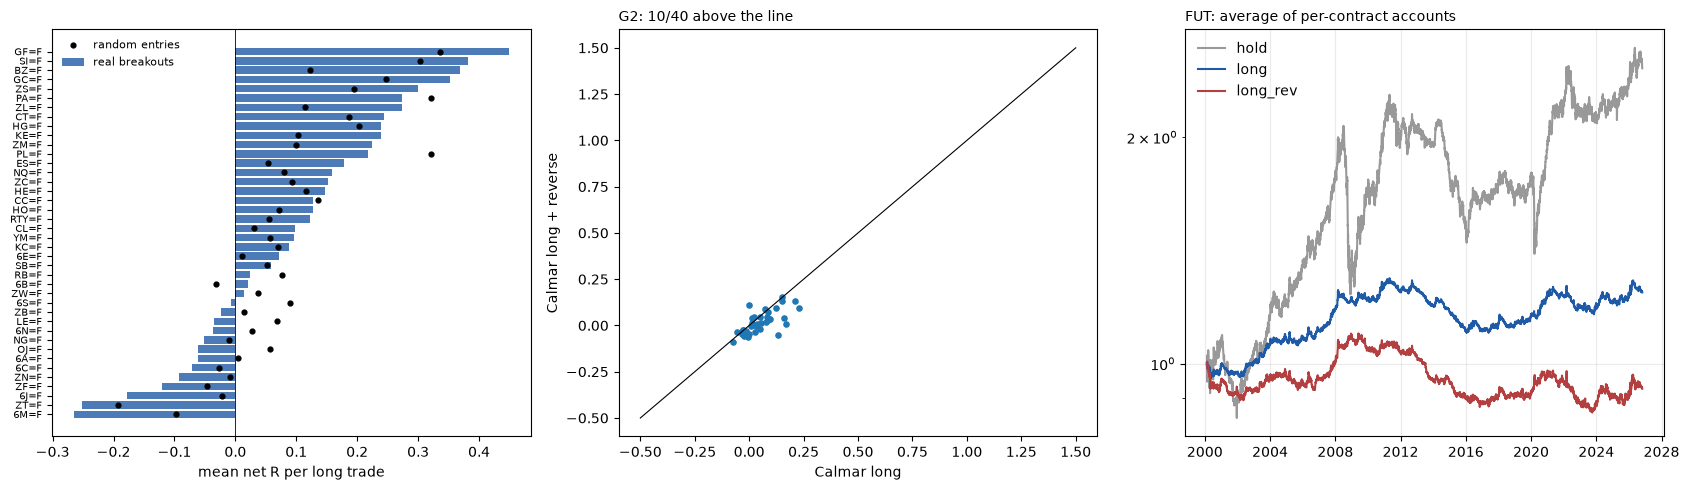

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
x = FUT.sort_values('mean_R_long'); y = np.arange(len(x))
axes[0].barh(y, x.mean_R_long, color='#1f5aa6', alpha=0.8, label='real breakouts'); axes[0].scatter(x.null_mean_R, y, color='k', s=12, zorder=3, label='random entries')
axes[0].set_yticks(y); axes[0].set_yticklabels(x.ticker, fontsize=7); axes[0].axvline(0, color='k', lw=0.6); axes[0].set_xlabel('mean net R per long trade'); axes[0].legend(frameon=False, fontsize=8)
lim = (-0.5, 1.5)
axes[1].scatter(FUT.L_calmar.clip(*lim), FUT.LR_calmar.clip(*lim), s=14); axes[1].plot(lim, lim, color='k', lw=0.8)
axes[1].set_xlabel('Calmar long'); axes[1].set_ylabel('Calmar long + reverse'); axes[1].set_title(f"G2: {DEC['reverse_better']}/{DEC['instruments']} above the line", loc='left', fontsize=10)
for v, col in (('hold', '0.6'), ('long', '#1f5aa6'), ('long_rev', '#b33f40')):
    s = POOL[('fut', v)]; axes[2].plot(s.index, s / 1e5, color=col, label=v)
axes[2].set_yscale('log'); axes[2].legend(frameon=False); axes[2].grid(alpha=0.25); axes[2].set_title('FUT: average of per-contract accounts', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Save

In [6]:
TAB.to_csv(OUT / '16_per_instrument.csv', index=False); DIST.to_csv(OUT / '16_distributions.csv'); SUMM.to_csv(OUT / '16_summary.csv')
SECT.to_csv(OUT / '16_sectors.csv'); AVG.to_csv(OUT / '16_average_of_accounts.csv')
(OUT / '16_decision.json').write_text(json.dumps({'decision_fut': DEC, 'etf_reported': DEC_ETF, 'registration': {**ta.registration(AP0), 'costs': COSTS},
                                                   'synthetic': SYNTHETIC}, indent=1, default=float))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '16_manifest.json').write_text(json.dumps({'version': ta.VERSION, 'git': git, 'python': platform.python_version(),
    'created_utc': pd.Timestamp.now('UTC').isoformat(), 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT (FUT):', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\16
VERDICT (FUT): NO_EDGE
